In [1]:
# Core Langgraph Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install langchain
!pip install pydantic
!pip install grandalf


In [2]:
import operator
from typing import Annotated, Literal, TypedDict, Optional
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from IPython.display import display,Image
import re

In [3]:
# Set up OpenAI API Key
# Please make sure you have your OpenAI API key stored as a secret named 'OPENAI_API_KEY'
import os
from google.colab import userdata

os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_APIKEY')

In [4]:
# ==========================================
# Step 1: Initialize LLM
# ==========================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)


In [5]:
# ===============================================================
# Step 2: Setup Structured output schema for the Supervisor LLM
# =================================================================

class SupervisorDecision(BaseModel):
    next_step: Literal["maths", "physics", "chemistry", "biology", "synthesizer"] = Field(
        description="Select 'maths' for maths, 'physics' for physics, 'chemistry' for chemistry, 'biology' for biology or 'synthesizer' if ready to finish."
    )
    reasoning: str = Field(description="Explanation of why this node was chosen.")

In [6]:
# ==========================================
# Step 3: Setup State
# ==========================================

class GraphState(TypedDict):
    task: str
    findings: Annotated[list[str], operator.add]
    next_step: Optional[str] # Make next_step optional
    final_report: Optional[str] # Make final_report optional

In [7]:
# ==========================================
# Step 4: Setup Mathematics Agent
# ==========================================

def maths_agent(state: GraphState):
    # Simulated work output
    return {"findings": ["I scored Score: 90/100 in Maths"]}

In [8]:
# ==========================================
# Step 5: Setup Physics Agent
# ==========================================

def physics_agent(state: GraphState):
    # Simulated work output
    return {"findings": ["I scored Score: 80/100 in Physics"]}

In [9]:
# ==========================================
# Step 6: Setup Chemistry Agent
# ==========================================

def chemistry_agent(state: GraphState):
    # Simulated work output
    return {"findings": ["I scored Score: 70/100 in Chemistry"]}

In [10]:
# ==========================================
# Step 7: Setup Biology Agent
# ==========================================

def biology_agent(state: GraphState):
    # Simulated work output
    return {"findings": ["I scored Score: 60/100 in Biology"]}

In [21]:
# ==========================================
# Step 8: Setup Supervisor Agent
# ==========================================

def supervisor_agent(state: GraphState):
    structured_llm = llm.with_structured_output(SupervisorDecision)
    task = state['task'].lower()
    print("task -->",task)
    findings = state.get('findings', [])
    print("findings -->",findings)

    # Explicitly define all possible subjects
    possible_subjects = ['maths', 'physics', 'chemistry', 'biology']

    # Determine which subjects are relevant to the current task
    all_subjects_in_task = [subj for subj in possible_subjects if subj in task]
    print("all_subjects_in_task -->",all_subjects_in_task)

    # Determine which subjects have already been covered in findings
    covered_subjects = []
    for f in findings:
        for subj in possible_subjects:
            if subj in f.lower():
                covered_subjects.append(subj)
    covered_subjects = list(set(covered_subjects))
    print("covered_subjects -->",covered_subjects)

    # Determine which subjects need to be processed
    remaining_subjects = [s for s in all_subjects_in_task if s not in covered_subjects]
    print("remaining_subjects -->",remaining_subjects)
    if not remaining_subjects:
        # If all relevant subjects are covered, route to synthesizer
        print("All subjects are covered, routing to synthesizer")
        decision = SupervisorDecision(next_step="synthesizer", reasoning="All requested subjects have been processed.")
    else:
        # Pick the next remaining subject
        print("Processing remaining subjects:", remaining_subjects[0])
        next_subject_to_process = remaining_subjects[0]
        decision_prompt = f"""
You are the Lead Orchestrator for the task: '{state['task']}'.
Findings collected so far: {state.get('findings', [])}
Subjects still needing processing: {remaining_subjects}.
Determine the next node to execute. You must select '{next_subject_to_process}' to continue processing remaining subjects.
"""
        print("decision_prompt -->",decision_prompt)
        decision = structured_llm.invoke(decision_prompt)
        # Force the decision to the next subject to process to ensure iteration
        decision.next_step = next_subject_to_process
        print("decision -->",decision)
        print("-"*80)
    return {"next_step": decision.next_step}

In [25]:
# ==========================================
# Step 9: Setup Synthesizer Agent
# ==========================================

def synthesizer_agent(state: GraphState):
    # Aggregate all state findings into a single prompt context
    collected_findings = "\n- ".join(state["findings"])

    prompt = f"""
    You are the Lead Synthesizer. Merge the following research findings into a
    cohesive executive summary for the topic: '{state['task']}'.
    Findings:
    - {collected_findings}
    Provide a clear final recommendation breakdown
    """
    response = llm.invoke(prompt)
    return {"final_report": response.content}
    print("-"*80)

In [26]:
# ==========================================
# Step 10: Setup Routing Function
# ==========================================

def route_next(state: GraphState) -> str:
    return state["next_step"]

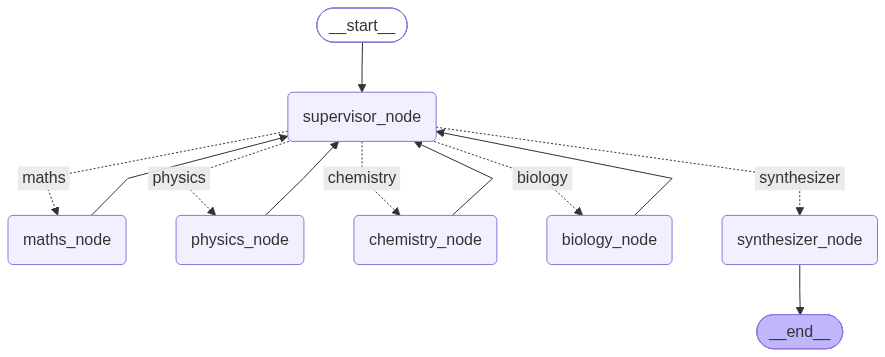

In [27]:
# ==========================================
# Step 11: Setup Graph
# ==========================================

workflow = StateGraph(GraphState)

# Add Nodes
workflow.add_node("supervisor_node", supervisor_agent)
workflow.add_node("maths_node", maths_agent)
workflow.add_node("physics_node", physics_agent)
workflow.add_node("chemistry_node", chemistry_agent)
workflow.add_node("biology_node", biology_agent)
workflow.add_node("synthesizer_node", synthesizer_agent)


# Add Edges
workflow.add_edge(START, "supervisor_node")
workflow.add_conditional_edges(
    "supervisor_node",
    route_next,
    {
        "maths": "maths_node",
        "physics": "physics_node",
        "chemistry": "chemistry_node",
        "biology": "biology_node",
        "synthesizer": "synthesizer_node" # Add synthesizer as a possible route from supervisor
    }
)
# All subject nodes now go back to the supervisor_node for iterative processing
workflow.add_edge("maths_node", "supervisor_node")
workflow.add_edge("physics_node", "supervisor_node")
workflow.add_edge("chemistry_node", "supervisor_node")
workflow.add_edge("biology_node", "supervisor_node")
workflow.add_edge("synthesizer_node", END)


executor = workflow.compile()

display(Image(executor.get_graph().draw_mermaid_png()))

In [28]:

# ==========================================
# Step 12: Run the Graph
# ==========================================

inputs = {"task": "How much did i score in maths,physics,chemistry and biology"}
output = executor.invoke(inputs)
print("="*80)
print("FINAL REPORT:\n", output["final_report"])
print("="*80)

task --> how much did i score in maths,physics,chemistry and biology
findings --> []
all_subjects_in_task --> ['maths', 'physics', 'chemistry', 'biology']
covered_subjects --> []
remaining_subjects --> ['maths', 'physics', 'chemistry', 'biology']
Processing remaining subjects: maths
decision_prompt --> 
You are the Lead Orchestrator for the task: 'How much did i score in maths,physics,chemistry and biology'.
Findings collected so far: []
Subjects still needing processing: ['maths', 'physics', 'chemistry', 'biology'].
Determine the next node to execute. You must select 'maths' to continue processing remaining subjects.

decision --> next_step='maths' reasoning="Since 'maths' is the first subject that needs processing, selecting it will allow us to continue with the task of determining scores in the remaining subjects."
--------------------------------------------------------------------------------
task --> how much did i score in maths,physics,chemistry and biology
findings --> ['I sco